# MFPCA amb correlació puntual entre X1 i X2

Autor: Leonel Fernando Nabaza Ruibal

**Pregunta:** si construïm $X^{(1)}$ i $X^{(2)}$ de manera que estiguin correlacionades
**només en el mateix instant** $t$ (i no entre instants diferents), és a dir

$$
\mathrm{corr}\big(X^{(1)}(t_j),\, X^{(2)}(t_i)\big) =
\begin{cases}
0.9 & \text{si } i=j\\
0 & \text{si } i\neq j
\end{cases}
$$

**es conserva aquesta correlació en les noves components principals (scores) quan
apliquem MFPCA?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from FDApy.representation.functional_data import DenseFunctionalData, MultivariateFunctionalData
from FDApy.representation.argvals import DenseArgvals
from FDApy.representation.values import DenseValues
from FDApy.preprocessing.dim_reduction.mfpca import MFPCA
from FDApy.preprocessing.dim_reduction.ufpca import UFPCA

np.random.seed(123)


---
# Part 1 — Funcions i generació de les dades

Fem servir funcions molt senzilles, amb una forma mitjana fixa (igual per a tots
els individus) i soroll:

$$
X^{(1)}(t) = \sin(t) + 0.5\,\varepsilon_1(t), \qquad
X^{(2)}(t) = 3\sin(t) + 0.5\,\varepsilon_2(t), \qquad t\in[0,2\pi]
$$

El truc per aconseguir la correlació **puntual** (només al mateix $t$) és generar,
**per a cada individu $i$ i cada instant $t$**, un parell de soroll
$(\varepsilon_1(t), \varepsilon_2(t))$ correlacionat amb $\rho=0.9$, però **fet de
manera independent** d'un instant $t$ a un altre. Així:

- si $i=j$ (mateix instant): $\mathrm{corr}(X^{(1)}(t_i), X^{(2)}(t_j)) = \rho = 0.9$
- si $i\neq j$ (instants diferents): $\mathrm{corr}(X^{(1)}(t_i), X^{(2)}(t_j)) = 0$

Aquesta és exactament l'estructura de soroll de la Part 1 del primer notebook, però
aquí ho comprovarem numèricament i estudiarem si la MFPCA la conserva.


In [2]:
n = 200
t = np.linspace(0, 2*np.pi, 100)
argvals = DenseArgvals({'input_dim_0': t})

rho = 0.9
Sigma = np.array([[1, rho], [rho, 1]])   # matriu de covariancies del soroll a cada t
L = np.linalg.cholesky(Sigma)

# soroll (n individus, len(t) instants, 2 variables), independent entre instants,
# correlacionat rho entre X1 i X2 dins del mateix instant
Z = np.random.standard_normal((n, len(t), 2))
eps = Z @ L.T

X1 = np.sin(t)[None, :]   + 0.5 * eps[..., 0]
X2 = 3*np.sin(t)[None, :] + 0.5 * eps[..., 1]


---
# Part 2 — Comprovació de l'estructura de correlació generada

Calculem la matriu de correlacions $\mathrm{corr}(X^{(1)}(t_i), X^{(2)}(t_j))$ per a
tots els parells $(i,j)$ i comprovem que és (aproximadament) la matriu identitat
multiplicada per $\rho=0.9$.


Correlació mitjana a la diagonal (i=j) : 0.9023
Correlació mitjana fora la diagonal    : 0.0558


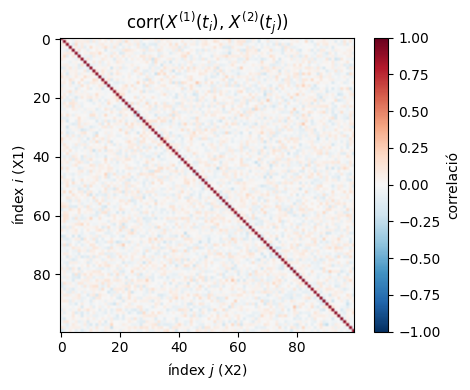

In [3]:
X1c = X1 - X1.mean(axis=0)
X2c = X2 - X2.mean(axis=0)

# matriu de correlacions creuades entre tots els instants (pot trigar uns segons)
C = np.corrcoef(X1c.T, X2c.T)[:len(t), len(t):]

print("Correlació mitjana a la diagonal (i=j) :", np.round(np.mean(np.diag(C)), 4))
print("Correlació mitjana fora la diagonal    :", np.round(np.mean(np.abs(C - np.diag(np.diag(C)))), 4))

plt.figure(figsize=(5, 4))
plt.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlació")
plt.title("corr($X^{(1)}(t_i)$, $X^{(2)}(t_j)$)")
plt.xlabel("índex $j$ (X2)")
plt.ylabel("índex $i$ (X1)")
plt.tight_layout()
plt.show()


## Construcció dels objectes funcionals

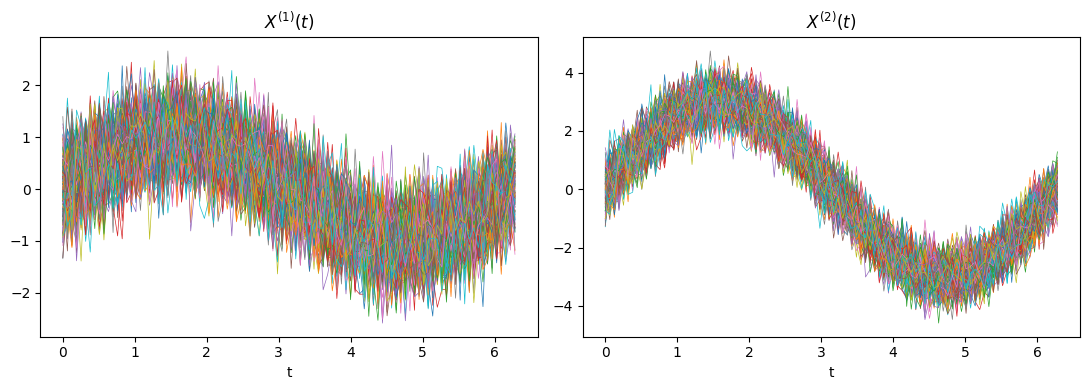

In [4]:
fd1 = DenseFunctionalData(argvals, DenseValues(X1))
fd2 = DenseFunctionalData(argvals, DenseValues(X2))
mData = MultivariateFunctionalData([fd1, fd2])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, X1.T, linewidth=0.5)
axes[0].set_title("$X^{(1)}(t)$")
axes[0].set_xlabel("t")
axes[1].plot(t, X2.T, linewidth=0.5)
axes[1].set_title("$X^{(2)}(t)$")
axes[1].set_xlabel("t")
plt.tight_layout()
plt.show()


---
# Part 3 — Ajust de la MFPCA i de la FPCA univariant per separat

Ajustem la MFPCA conjunta (Happ & Greven) sobre $(X^{(1)}, X^{(2)})$, i també una FPCA
univariant **per separat** sobre $X^{(1)}$ i sobre $X^{(2)}$: així podrem comparar els
seus scores component a component.


In [5]:
K = 5  # nombre de components a estudiar

# MFPCA conjunta
uniExpansions = [
    {'method': 'UFPCA', 'n_components': 10},
    {'method': 'UFPCA', 'n_components': 10},
]
mfpca = MFPCA(n_components=K, method='covariance', univariate_expansions=uniExpansions)
mfpca.fit(mData)

print("Valors propis MFPCA:", np.round(mfpca.eigenvalues, 4))


Valors propis MFPCA: [0.0445 0.0432 0.0397 0.0387 0.0361]


In [6]:
# FPCA univariant per separat sobre cada element
ufpca1 = UFPCA(n_components=K, method='covariance')
ufpca1.fit(fd1)
scores1 = ufpca1.transform(fd1)

ufpca2 = UFPCA(n_components=K, method='covariance')
ufpca2.fit(fd2)
scores2 = ufpca2.transform(fd2)

print("Valors propis X1:", np.round(ufpca1.eigenvalues, 4))
print("Valors propis X2:", np.round(ufpca2.eigenvalues, 4))


Valors propis X1: [0.0432 0.0415 0.0406 0.04   0.0384]
Valors propis X2: [0.0451 0.0443 0.0409 0.0402 0.0386]


---
# Part 4 — Es conserva la correlació en les noves PCs?

Comparem la correlació original ($\rho=0.9$, puntual) amb la correlació entre els
scores de la component $k$ de $X^{(1)}$ i de $X^{(2)}$ per a cada $k$.


Correlació original (puntual, rho): 0.9

Correlació entre scores(X1, comp k) i scores(X2, comp k):
  Component 1: 0.5144
  Component 2: -0.5876
  Component 3: 0.6323
  Component 4: 0.4017
  Component 5: 0.4169


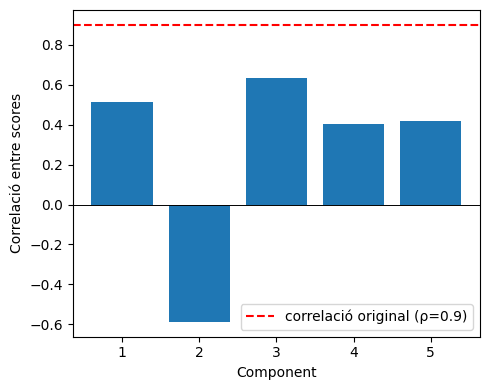

In [7]:
print(f"Correlació original (puntual, rho): {rho}\n")

print("Correlació entre scores(X1, comp k) i scores(X2, comp k):")
corr_scores = []
for k in range(K):
    c = np.corrcoef(scores1[:, k], scores2[:, k])[0, 1]
    corr_scores.append(c)
    print(f"  Component {k+1}: {c:.4f}")

plt.figure(figsize=(5, 4))
plt.bar(range(1, K+1), corr_scores)
plt.axhline(rho, color="red", linestyle="--", label=f"correlació original (ρ={rho})")
plt.axhline(0, color="black", linewidth=0.7)
plt.xlabel("Component")
plt.ylabel("Correlació entre scores")
plt.legend()
plt.tight_layout()
plt.show()


---
# Conclusió

La correlació puntual ($\rho=0.9$, només al mateix instant $t$) **no es conserva**
en les components principals: la correlació entre els scores de cada component és
molt inferior a 0.9 i, a més, no té un signe ni una magnitud consistent entre
components.

La raó és que la FPCA (i, per tant, la MFPCA) busca **modes de variació suaus i
globals** (funcions que expliquen la major variància possible al llarg de tot el
domini), mentre que la correlació que hem imposat és **local i puntual** (soroll
independent instant a instant). A més, els valors propis de X1, X2 i de la MFPCA
són gairebé plans (no decreixen clarament), símptoma que aquest tipus de soroll no
té una estructura de baixa dimensió que la FPCA pugui capturar amb poques
components — exactament el que ja intuíem al primer notebook ("en aquest tipus
d'exemple no podem extreure massa informació de les components generades").
